# 08_02 — Virtual BCM from the camera image: CNN autoencoder + LSTM, image only and image + features

`BCM_GUN` of a shot from **the BTV0125 camera images only**, with the colleague's pipeline
(`scripts/CNN_from_BTV.py`, `scripts/LSTM_from_Latentspace.py`):

1. **CNN autoencoder** (`CNN_from_BTV.AutoEncoder`, imported as is): image → 16 latent numbers → reconstructed image,
   trained without labels on the reconstruction (`weighted_mse`: bright pixels up-weighted, so the spot is not drowned
   by the black background). CoordConv input channels, so the latent keeps the spot position.
2. **Latents** of every image (the encoder only).
3. **vBCM heads** on the latents:
   - **latent MLP**: the 16 latents of the shot → BCM (the MLP of notebook 08);
   - **latent LSTM**: the latents of the last `T` shots → BCM. Same network as `LatentLSTM` in
     `LSTM_from_Latentspace.py` (LSTM with `HIDDEN` units, linear output), but the output is the BCM instead of the
     next latent vector: the script's LSTM predicts the next image, not the charge.
4. **Latents + the 10 dataset features** (`results/datasets/segment_*.npz`: camera, laser and RF, the features of
   08): the 16 latents and the 10 features of each shot side by side (26 inputs), then the same LSTM on the last `T`
   shots (**latent + features LSTM**). Controls: the same LSTM on the 10 features only (**features LSTM**: what the
   history adds to the features) and the MLP on the 26 inputs of the shot (**latent + features MLP**: what the
   history adds to the combination). Not image only any more: the laser and RF are inputs.

**Training length:** the first run (at most 40 epochs, patience 5) stopped while the validation reconstruction loss was
still falling. The autoencoders are now trained for up to `EPOCHS_AE` = 300 epochs, with the learning rate halved on a
plateau and a longer patience (see the autoencoder section).

**Comparable with 08 and 08_01:**
- **Rows and test shots of 08:** the `valid` rows with a beam on the camera, the last `TEST_FRAC` = 20 % of each
  segment's shots are the test set (identical test shots as 08's tables).
- **One model per charge regime, as 08_01**, trained on all of that regime's segments together. Early stopping on the
  last 10 % of each segment's training part, never the test set. The autoencoder sees training images only.
- **Model names:** `… MLP` = one shot; `… LSTM` = the last `T` shots up to the current one.
- **References on the same test shots:** each segment's training mean; an MLP on the hand-crafted camera features of
  the datasets (`BTV_*`, `SVD_*`: image only too); and an MLP on all 10 features (camera + laser + RF, as 08: not
  image only, for context).

**Images:** the datasets hold no images, so they are read again from the raw h5 files (preprocessing below) and
cached. Needs a GPU: run it on a reservation node (`jupyter.sbatch` asks for one).

In [1]:
import hashlib
import json
import os
import sys
import time
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from joblib import Parallel, delayed
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATASETS = REPO / "results" / "datasets"
IMAGES = REPO / "results" / "images"                  # image cache of this notebook
sys.path.insert(0, str(REPO / "scripts"))
import CNN_from_BTV as cnn                            # the colleague's autoencoder

DATA_CANDIDATES = [os.environ.get("FA_DATA_ROOT"), "/lustre/work/pdl18409/shared/data/optimisation/measured_data",
                   "/data/optimisation/measured_data"]
data_root = next(Path(p) for p in DATA_CANDIDATES if p and Path(p).is_dir())

# the three regimes of the clean data, as in 08_01, by segment number
REGIMES = {"low charge": [0, 2, 3, 4], "high, repetitive": [5], "high, non-repetitive": [1, 6, 7]}
REGIME_OF = {s: r for r, segs in REGIMES.items() for s in segs}
TEST_FRAC = 0.2    # as 08: the last 20 % of each segment's shots are the test set
VAL_FRAC = 0.1     # early stopping on the last 10 % of each segment's training part (as 08_01)

# images: a 300 x 400 px window around the beam (rows ~565-760, cols ~845-1025 in every segment; the script's
# "center" crop, rows 458-758, would cut the spot), binned 2 x 2 -> 150 x 200
CROP = (slice(505, 805), slice(735, 1135))
BIN = 2
BG_ROWS = slice(0, 150)                               # background: median of the top rows, as extract_features.py
cnn.H, cnn.W = 300 // BIN, 400 // BIN                 # the decoder's output size (module globals of the script)
N_JOBS = min(32, os.cpu_count() or 1)

# training
DEVICE = cnn.DEVICE
EPOCHS_AE, PATIENCE_AE, BATCH_AE, LR_AE = 300, 20, 128, 1e-3      # 40, 5 in the first run: stopped too early
LR_DECAY, LR_PATIENCE, LR_MIN = 0.5, 6, 1e-5     # learning rate x LR_DECAY after LR_PATIENCE epochs without improvement
T, HIDDEN, EPOCHS_LSTM, PATIENCE_LSTM, BATCH_LSTM, LR_LSTM = 10, 64, 100, 10, 256, 1e-3
torch.set_num_threads(8)
print(f"device {DEVICE}" + (f" ({torch.cuda.get_device_name()})" if DEVICE == "cuda" else " -- no GPU: the autoencoder will be very slow"))

device cuda (NVIDIA GB200)


## Shots and split

The datasets give the shots in time order, the BCM, the flags and the hand-crafted features. Per segment:
- **usable:** `valid` and a beam on the camera (the rows of 08);
- **test:** the last `TEST_FRAC` of the segment's shots;
- **val:** the last `VAL_FRAC` of the usable training shots (early stopping); **train:** the rest.

In [2]:
manifest = json.loads((DATASETS / "manifest.json").read_text())
FEATURES = manifest["features"]
CAMERA = [f for f in FEATURES if f.startswith(("BTV_", "SVD_"))]

parts = []
for info in manifest["segments"]:
    d = np.load(DATASETS / info["file"])
    p = pd.DataFrame(d["X"], columns=d["features"])
    p["lab_laser_power"] *= 1e6                                       # J -> µJ, see 08
    p["BCM_GUN"] = d["y"]
    for k in ["run", "chunk", "shot_in_chunk"]:
        p[k] = d[k]
    p["seg"], p["pos"] = info["segment"], np.arange(len(p))
    p["test"] = p["pos"] >= int(len(p) * (1 - TEST_FRAC))
    p["usable"] = d["valid"] & p[FEATURES].notna().all(axis=1).to_numpy()
    k = (p["usable"] & ~p["test"]).cumsum()
    p["val"] = p["usable"] & ~p["test"] & (k > (1 - VAL_FRAC) * k.max())
    parts.append(p)
df = pd.concat(parts, ignore_index=True)
df["regime"] = df["seg"].map(REGIME_OF)
df["train"] = df["usable"] & ~df["test"] & ~df["val"]
df["scored"] = df["usable"] & df["test"]

df.groupby("seg").agg(regime=("regime", "first"), shots=("pos", "size"), train=("train", "sum"), val=("val", "sum"),
                      test=("scored", "sum"), BCM_mean_nC=("BCM_GUN", "mean")).round(3)

,regime,shots,train,val,test,BCM_mean_nC
seg,,,,,,
0,low charge,6027,3262,363,948,0.223
1,"high, non-repetitive",19400,11406,1268,3732,4.829
2,low charge,200,110,13,31,0.144
3,low charge,7100,3820,425,1125,0.122
4,low charge,4500,2727,304,746,0.101
5,"high, repetitive",20000,12136,1349,3927,5.460
6,"high, non-repetitive",4100,2273,253,611,5.506
7,"high, non-repetitive",2000,1277,142,359,10.096


## Camera images from the raw files

Per shot: the `CROP` window of `BTV0125/image2D`, minus the background (median of the top rows), binned
`BIN` × `BIN`, negative pixels set to 0, stored as float16 counts. One parallel pass over the chunks (a few minutes),
cached in `results/images/` (~4 GB) and reused while the shots are unchanged. Row `i` of the cache is row `i` of
`df`.

images: cached /lustre/work/pdl18409/shared/data/optimisation/teams/fast-approximate/Fast-Approximate/results/images/btv0125_crop150x200.npy
(63327, 150, 200) float16 3.8 GB


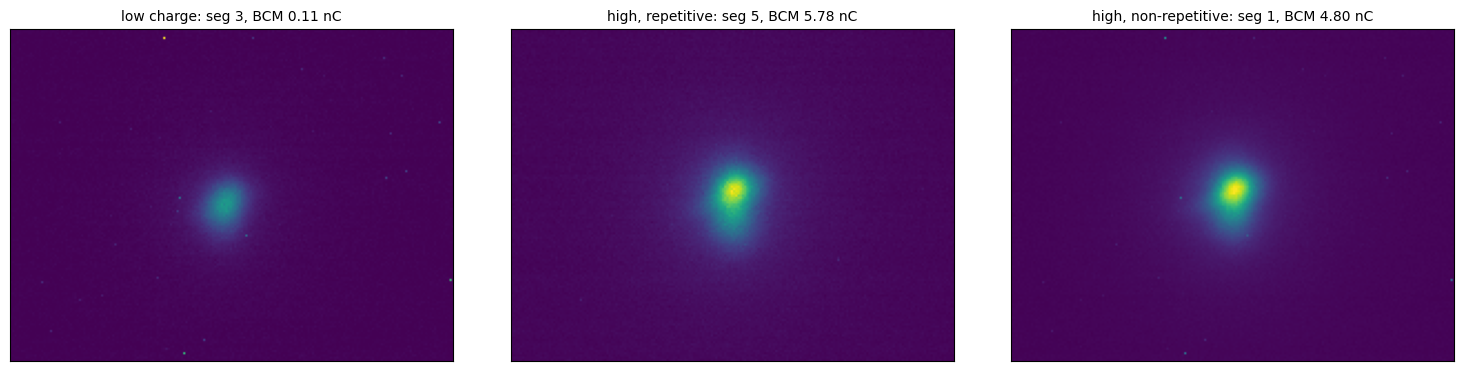

In [3]:
def chunk_images(fp):
    # Worker, one chunk -> (shots, H, W) float16 background-subtracted, binned counts
    with h5py.File(fp, "r") as f:
        ds = f["BTV0125/image2D"]
        img = ds[:, CROP[0], CROP[1]].astype(np.float32)
        bg = np.median(ds[:, BG_ROWS, :].reshape(len(img), -1), axis=1)
    img -= bg[:, None, None]
    n, h, w = img.shape
    img = img.reshape(n, h // BIN, BIN, w // BIN, BIN).mean(axis=(2, 4))
    return np.clip(img, 0, None).astype(np.float16)


CACHE = IMAGES / f"btv0125_crop{cnn.H}x{cnn.W}.npy"
INDEX = CACHE.with_suffix(".index.npz")
signature = (df["run"] + "/" + df["chunk"].astype(str) + "/" + df["shot_in_chunk"].astype(str)).to_numpy(dtype=str)
if CACHE.exists() and INDEX.exists() and np.array_equal(np.load(INDEX)["signature"], signature):
    images = np.load(CACHE)
    print(f"images: cached {CACHE}")
else:
    chunks = list(dict.fromkeys(zip(df["run"], df["chunk"])))       # in df order
    files = [data_root / run / "h5" / f"chunk_{c:05d}.h5" for run, c in chunks]
    t0 = time.time()
    parts = Parallel(n_jobs=N_JOBS, verbose=1)(delayed(chunk_images)(fp) for fp in files)
    sizes = df.groupby(["run", "chunk"], sort=False).size().to_numpy()
    assert [len(p) for p in parts] == list(sizes), "chunk sizes differ between the datasets and the h5 files"
    images = np.concatenate(parts)
    del parts
    IMAGES.mkdir(parents=True, exist_ok=True)
    np.save(CACHE, images)
    np.savez(INDEX, signature=signature)
    print(f"images: {len(images)} read in {time.time() - t0:.0f} s -> {CACHE}")
print(images.shape, images.dtype, f"{images.nbytes / 1e9:.1f} GB")

# one usable shot per regime, from the middle of its shots
fig, axes = plt.subplots(1, len(REGIMES), figsize=(5 * len(REGIMES), 3.6), layout="constrained")
for ax, (rname, segs) in zip(axes, REGIMES.items()):
    usable = df.index[df["usable"] & df["seg"].isin(segs)]
    i = usable[len(usable) // 2]
    ax.imshow(images[i].astype(np.float32), cmap="viridis")
    ax.set_title(f"{rname}: seg {df['seg'][i]}, BCM {df['BCM_GUN'][i]:.2f} nC", fontsize=10)
    ax.set_xticks([]), ax.set_yticks([])
plt.show()

## Autoencoder, one per regime

The colleague's `AutoEncoder` and `weighted_mse`, with a training loop for ~20 000 images instead of the script's
100: images on the GPU, batches of `BATCH_AE`, bfloat16 autocast, and early stopping on the reconstruction loss of
the validation images (at most `EPOCHS_AE` epochs, `PATIENCE_AE` without improvement, best epoch kept).
- **Longer training:** with 40 epochs and patience 5 the first run stopped while the validation loss was still
  falling: two regimes stopped on a noisy epoch, and the high non-repetitive one ran into the 40-epoch cap. Now
  `EPOCHS_AE` = 300 at most and `PATIENCE_AE` = 20, and the learning rate is halved (`LR_DECAY`) after `LR_PATIENCE`
  epochs without improvement, down to `LR_MIN`. That way the loss settles instead of bouncing at the initial rate.
  The first run's cache is kept as `results/images/08_02_autoencoders_40ep.pt`.
- **Scaling:** as the script, one constant for all images of a regime, so the relative brightness between shots (the
  charge information) is kept. The script divides by the maximum pixel; here by the 99.9th percentile of the
  training images' maxima (one hot pixel would otherwise set it), clipped at 1 (the decoder ends in a sigmoid).
- **Trained on the training images only** (no test images), no labels: the script's optional `aux_head` is unused.
- Then the latents of **all** the regime's shots (test included: the encoder is fixed by then).
- The latents, loss curves, example reconstructions and weights are cached in `results/images/08_02_autoencoders.pt`
  (see the training times printed below, on one GB200), reused while the shots and these settings are unchanged.

In [4]:
def train_autoencoder(X, fit, val):
    # X: (n, 1, H, W) float16 on DEVICE, in [0, 1]; fit, val: index tensors -> best model, loss history
    torch.manual_seed(0)
    model = cnn.AutoEncoder().to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR_AE)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=LR_DECAY, patience=LR_PATIENCE, min_lr=LR_MIN)
    amp = dict(device_type=DEVICE, dtype=torch.bfloat16, enabled=DEVICE == "cuda")

    def val_loss():
        model.eval()
        with torch.no_grad(), torch.autocast(**amp):
            return float(sum(cnn.weighted_mse(model(X[b].float())[0].float(), X[b].float()) * len(b)
                             for b in val.split(1024)) / len(val))

    best, state, wait, hist, best_ep, t_start = val_loss(), None, 0, [], 0, time.time()
    for ep in range(1, EPOCHS_AE + 1):
        model.train()
        t0, tot = time.time(), 0.0
        for b in fit[torch.randperm(len(fit), device=fit.device)].split(BATCH_AE):
            x = X[b].float()
            with torch.autocast(**amp):
                rec = model(x)[0]
            loss = cnn.weighted_mse(rec.float(), x)
            opt.zero_grad()
            loss.backward()
            opt.step()
            tot += loss.item() * len(b)
        v = val_loss()
        sched.step(v)
        hist.append((tot / len(fit), v))
        improved = v < best
        if improved:
            best, wait, best_ep = v, 0, ep
            state = {k: t.detach().clone() for k, t in model.state_dict().items()}
        else:
            wait += 1
        if ep % 10 == 0 or ep == 1:                                     # every 10th epoch, the full curve is plotted below
            print(f"  epoch {ep:3d} | train {hist[-1][0]:.6f} | val {v:.6f}{' *' if improved else ''} "
                  f"| lr {opt.param_groups[0]['lr']:.1e} | {time.time() - t0:.0f} s")
        if wait >= PATIENCE_AE:
            break
    print(f"  stopped after {ep} epochs ({(time.time() - t_start) / 60:.0f} min): best val {best:.6f} at epoch {best_ep}")
    if state is not None:
        model.load_state_dict(state)
    return model.eval(), hist


@torch.no_grad()
def encode(model, X):
    with torch.autocast(device_type=DEVICE, dtype=torch.bfloat16, enabled=DEVICE == "cuda"):
        return torch.cat([model.encoder(X[i:i + 1024].float()).float() for i in range(0, len(X), 1024)]).cpu().numpy()


LAT = [f"z{k + 1}" for k in range(cnn.LATENT)]
AE_CACHE = IMAGES / "08_02_autoencoders.pt"                         # reused while shots and settings are unchanged
config = dict(shots=hashlib.md5("|".join(signature).encode()).hexdigest(), crop=str(CROP), bin=BIN, regimes=REGIMES,
              test=TEST_FRAC, val=VAL_FRAC, train=(EPOCHS_AE, PATIENCE_AE, BATCH_AE, LR_AE, LR_DECAY, LR_PATIENCE, LR_MIN),
              latent=cnn.LATENT)
cached = torch.load(AE_CACHE, weights_only=False) if AE_CACHE.exists() else None
if cached is not None and cached["config"] == config:
    latents = pd.DataFrame(cached["latents"], index=df.index, columns=LAT)
    history, examples = cached["history"], cached["examples"]
    print(f"autoencoders: cached {AE_CACHE}")
    todo = []
else:
    latents = pd.DataFrame(np.nan, index=df.index, columns=LAT)
    history, examples, weights = {}, {}, {}
    todo = list(REGIMES.items())
for rname, segs in todo:
    rows = df.index[df["seg"].isin(segs)].to_numpy()
    tr, va = df.loc[rows, "train"].to_numpy(), df.loc[rows, "val"].to_numpy()
    scale = float(np.percentile(images[rows[tr]].reshape(tr.sum(), -1).max(axis=1), 99.9))
    X = torch.from_numpy(np.clip(images[rows] / np.float16(scale), 0, 1)).unsqueeze(1).to(DEVICE)
    fit, val = (torch.from_numpy(np.flatnonzero(m)).to(DEVICE) for m in (tr, va))
    print(f"{rname}: {len(rows)} images ({tr.sum()} fit, {va.sum()} val), scale {scale:.0f} counts")
    model, history[rname] = train_autoencoder(X, fit, val)
    weights[rname] = {k: t.cpu() for k, t in model.state_dict().items()}
    latents.loc[rows] = encode(model, X)
    i = int(np.flatnonzero(df.loc[rows, "scored"].to_numpy())[0])  # first test shot of the regime
    with torch.no_grad():
        examples[rname] = (X[i, 0].float().cpu().numpy(), model(X[i:i + 1].float())[0][0, 0].float().cpu().numpy(),
                           df["seg"][rows[i]])
    del X, model
    torch.cuda.empty_cache() if DEVICE == "cuda" else None
    if rname == todo[-1][0]:
        torch.save(dict(config=config, latents=latents.to_numpy(), history=history, examples=examples, weights=weights), AE_CACHE)
        print(f"-> {AE_CACHE}")

low charge: 17827 images (9919 fit, 1105 val), scale 2532 counts


  epoch  1 | train 0.162892 | val 0.047542 * | 9 s


  epoch  2 | train 0.025220 | val 0.011362 * | 8 s


  epoch  3 | train 0.008312 | val 0.005904 * | 8 s


  epoch  4 | train 0.004252 | val 0.003305 * | 8 s


...

  epoch 37 | train 0.000717 | val 0.000947 | 13 s


  epoch 38 | train 0.000684 | val 0.000821 * | 13 s


  epoch 39 | train 0.000692 | val 0.000758 * | 13 s


  epoch 40 | train 0.000659 | val 0.000830 | 13 s


-> /lustre/work/pdl18409/shared/data/optimisation/teams/fast-approximate/Fast-Approximate/results/images/08_02_autoencoders.pt


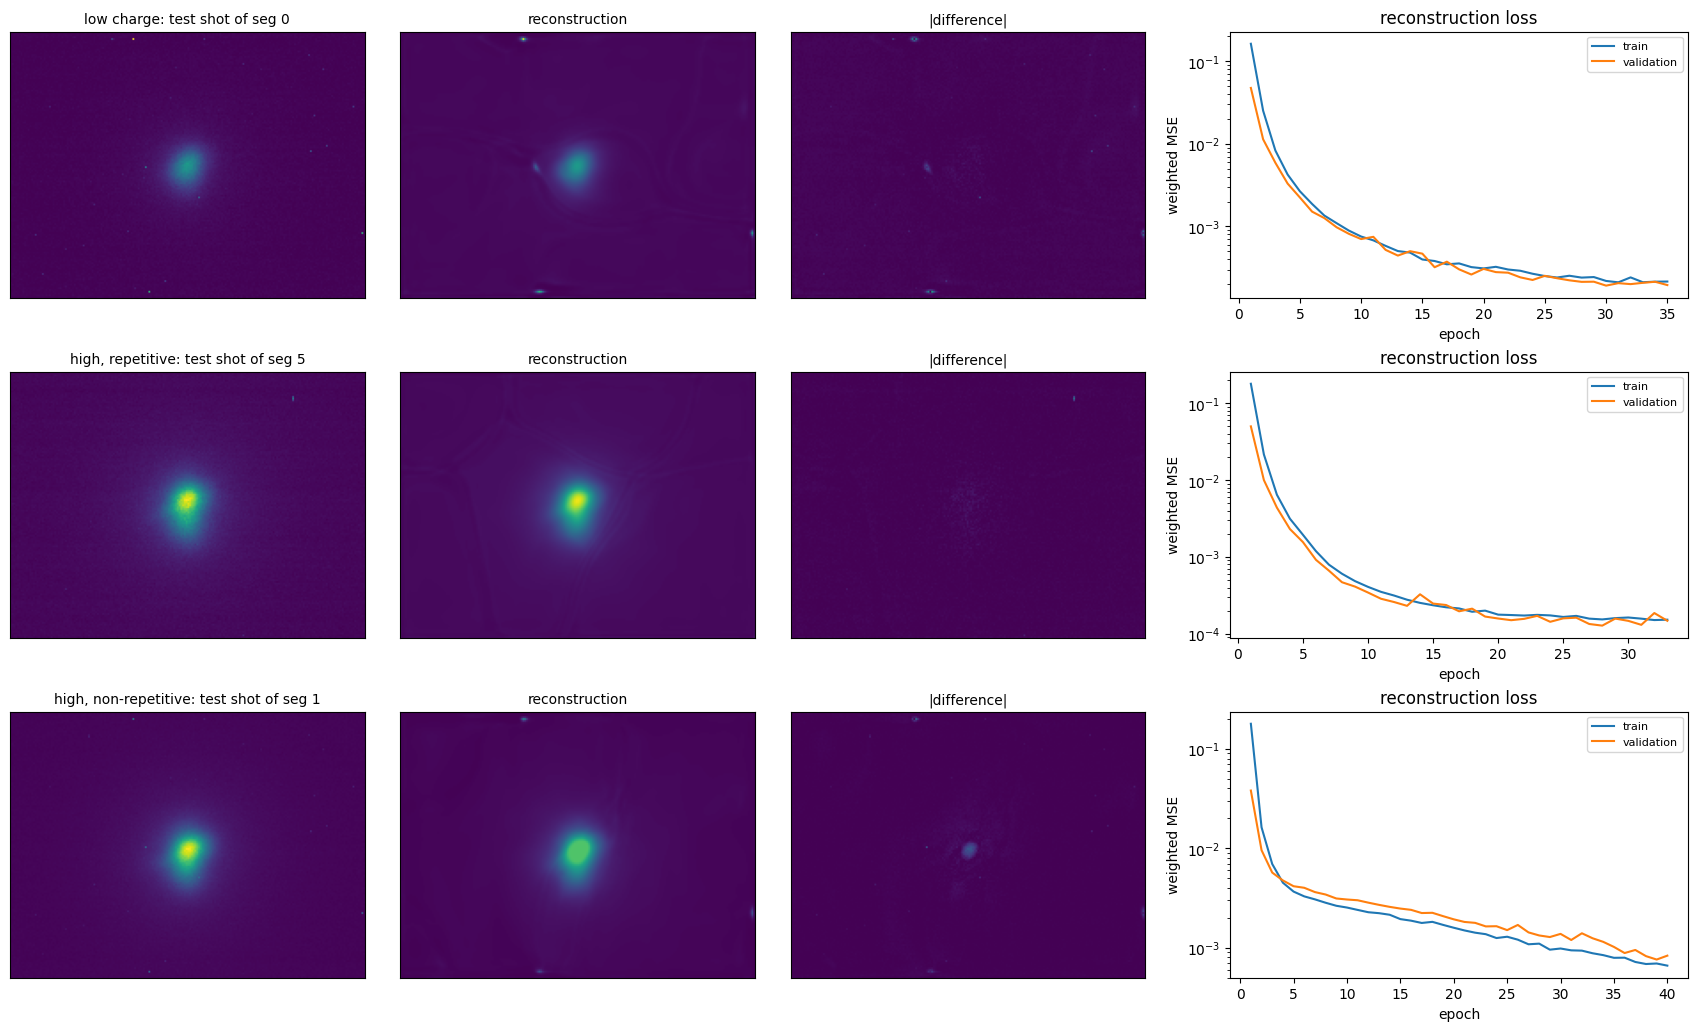

,z1,z2,z3,z4,z5,z6,z7,z8,z9,z10,z11,z12,z13,z14,z15,z16
low charge,0.09,0.20,0.09,0.41,0.13,0.19,0.04,0.16,0.24,0.22,0.09,0.07,0.07,0.27,0.10,0.42
"high, repetitive",0.22,0.40,0.21,0.11,0.50,0.10,0.11,0.34,0.11,0.27,0.34,0.37,0.18,0.21,0.16,0.12
"high, non-repetitive",0.03,0.06,0.55,0.17,0.10,0.45,0.31,0.05,0.47,0.35,0.06,0.39,0.42,0.02,0.17,0.22


In [5]:
fig, axes = plt.subplots(len(REGIMES), 4, figsize=(17, 3.4 * len(REGIMES)), layout="constrained",
                         gridspec_kw={"width_ratios": [1, 1, 1, 1.2]})
for (a0, a1, a2, a3), (rname, (img, rec, s)) in zip(axes, examples.items()):
    for ax, im, title in [(a0, img, f"{rname}: test shot of seg {s}"), (a1, rec, "reconstruction"),
                          (a2, np.abs(img - rec), "|difference|")]:
        ax.imshow(im, cmap="viridis", vmin=0, vmax=max(img.max(), 1e-3))
        ax.set_title(title, fontsize=10)
        ax.set_xticks([]), ax.set_yticks([])
    h = np.array(history[rname])
    a3.plot(np.arange(1, len(h) + 1), h[:, 0], label="train")
    a3.plot(np.arange(1, len(h) + 1), h[:, 1], label="validation")
    a3.set(xlabel="epoch", ylabel="weighted MSE", title="reconstruction loss", yscale="log")
    a3.legend(fontsize=8)
plt.show()

# how much of the charge the single latents carry, before any head: |r| with the BCM on the training shots
pd.DataFrame({rname: latents[df["train"] & df["seg"].isin(segs)].corrwith(df["BCM_GUN"]).abs()
              for rname, segs in REGIMES.items()}).T.round(2)

## vBCM heads and references

All trained per regime on the `train` shots, scored on the test shots of each segment (`scored`).
- **segment mean:** the segment's training mean (the "train mean" of 08).
- **camera features / all features / latent MLP / latent + features MLP:** the MLP of notebook 08 (inputs and
  target standardised, 32 → 16 ReLU units, its own early stopping) on the hand-crafted camera features, on all 10
  features, on the 16 latents, or on the 16 latents and the 10 features (26 inputs).
- **latent LSTM / features LSTM / latent + features LSTM:** the `LatentLSTM` network of the script with a BCM output,
  on windows of the last `T` shots' inputs: the 16 latents, the 10 dataset features, or both (26). The newest step
  is the current shot. A window never reaches into the previous segment, and steps before the segment start are
  zeros. Inputs and BCM standardised on the training shots. The earlier shots of a window may be unusable (no beam,
  invalid); their missing features are set to 0 (= the training mean), as the latents of such shots are kept too.
  Adam, MSE loss as the script, batches of `BATCH_LSTM`, early stopping on the validation shots (`PATIENCE_LSTM`
  epochs, best kept).

In [6]:
def mlp():
    return TransformedTargetRegressor(
        regressor=make_pipeline(StandardScaler(),
                                MLPRegressor(hidden_layer_sizes=(32, 16), activation="relu", alpha=1e-3,
                                             learning_rate_init=1e-3, max_iter=2000, early_stopping=True,
                                             validation_fraction=0.2, n_iter_no_change=30, random_state=0)),
        transformer=StandardScaler())


class BCMLSTM(torch.nn.Module):
    # LatentLSTM of LSTM_from_Latentspace.py with a 1-value output: the BCM instead of the next latent vector
    def __init__(self, latent, hidden=HIDDEN):
        super().__init__()
        self.lstm = torch.nn.LSTM(latent, hidden, batch_first=True)
        self.out = torch.nn.Linear(hidden, 1)

    def forward(self, z_seq):                                         # (B, T, latent)
        h, _ = self.lstm(z_seq)
        return self.out(h[:, -1]).squeeze(-1)


def lstm_predict(rows, X):
    # LSTM on the windows of the inputs X (latents and/or features) of the regime's rows -> predicted BCM (nC) there
    tr, va = df.loc[rows, "train"].to_numpy(), df.loc[rows, "val"].to_numpy()
    Z = X.loc[rows].to_numpy(np.float32)
    Z = np.nan_to_num((Z - Z[tr].mean(0)) / (Z[tr].std(0) + 1e-6))   # NaN features of unusable shots -> training mean
    A = torch.from_numpy(np.vstack([Z, np.zeros((1, Z.shape[1]), np.float32)])).to(DEVICE)   # + a zero pad row
    pos, lag = df.loc[rows, "pos"].to_numpy(), np.arange(T - 1, -1, -1)
    I = torch.from_numpy(np.where(pos[:, None] >= lag, np.arange(len(rows))[:, None] - lag, len(rows))).to(DEVICE)
    y = df.loc[rows, "BCM_GUN"].to_numpy(np.float32)
    mu, sd = y[tr].mean(), y[tr].std()
    Y = torch.from_numpy((y - mu) / sd).to(DEVICE)
    fit, val = (torch.from_numpy(np.flatnonzero(m)).to(DEVICE) for m in (tr, va))

    torch.manual_seed(0)
    model = BCMLSTM(Z.shape[1]).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR_LSTM)
    predict = lambda b: torch.cat([model(A[I[c]]) for c in b.split(8192)])
    best, state, wait = np.inf, None, 0
    for ep in range(1, EPOCHS_LSTM + 1):
        model.train()
        for b in fit[torch.randperm(len(fit), device=fit.device)].split(BATCH_LSTM):
            loss = torch.nn.functional.mse_loss(model(A[I[b]]), Y[b])
            opt.zero_grad()
            loss.backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            v = (predict(val) - Y[val]).abs().mean().item()
        if v < best:
            best, wait, state = v, 0, {k: t.detach().clone() for k, t in model.state_dict().items()}
        else:
            wait += 1
            if wait >= PATIENCE_LSTM:
                break
    model.load_state_dict(state)
    model.eval()
    with torch.no_grad():
        out = predict(torch.arange(len(rows), device=DEVICE)).cpu().numpy()
    print(f"  LSTM on {Z.shape[1]} inputs: {ep} epochs, best validation MAE {best * sd * 1000:.1f} pC")
    return pd.Series(out * sd + mu, index=rows)


inputs = pd.concat([latents, df[FEATURES]], axis=1)                 # the 16 latents and the 10 dataset features
preds = {}
for rname, segs in REGIMES.items():
    print(rname)
    rows = df.index[df["seg"].isin(segs)]
    tr = df.loc[rows, "train"] | df.loc[rows, "val"]                  # the sklearn MLP does its own early stopping
    p = {"segment mean": df.loc[rows, "seg"].map(df[df["train"] | df["val"]].groupby("seg")["BCM_GUN"].mean())}
    for name, cols, X in [("camera features", CAMERA, df), ("all features", FEATURES, df), ("latent MLP", LAT, latents),
                          ("latent + features MLP", LAT + FEATURES, inputs)]:
        m = mlp().fit(X.loc[rows[tr.to_numpy()], cols], df.loc[rows[tr.to_numpy()], "BCM_GUN"])
        use = rows[df.loc[rows, "usable"].to_numpy()]                  # no NaN features there
        p[name] = pd.Series(m.predict(X.loc[use, cols]), index=use)
    for name, X in [("latent LSTM", latents), ("features LSTM", df[FEATURES]), ("latent + features LSTM", inputs)]:
        p[name] = lstm_predict(rows.to_numpy(), X)
    preds[rname] = p
MODELS = list(next(iter(preds.values())))

low charge


  LSTM: 27 epochs, best validation MAE 12.7 pC
high, repetitive


  LSTM: 21 epochs, best validation MAE 93.0 pC
high, non-repetitive


  LSTM: 15 epochs, best validation MAE 178.1 pC


## Results

Same layout and test shots as the all-segments tables of 08. Image only: `camera features`, `latent MLP`,
`latent LSTM`. The others also use the laser and RF features. Best per segment in bold, across all columns.

In [7]:
rows, curves = [], {}
for rname, segs in REGIMES.items():
    for s in segs:
        i = df.index[df["scored"] & (df["seg"] == s)]
        y = df.loc[i, "BCM_GUN"]
        row = {("", "regime"): rname, ("", "train"): int((df["train"] | df["val"])[df["seg"] == s].sum()),
               ("", "test"): len(i), ("", "BCM mean (pC)"): 1000 * y.mean(), ("", "BCM std (pC)"): 1000 * y.std()}
        for name in MODELS:
            row[("MAE (pC)", name)] = 1000 * mean_absolute_error(y, preds[rname][name][i])
        for name in MODELS:
            row[("R2", name)] = r2_score(y, preds[rname][name][i])
        rows.append(pd.Series(row, name=s))
        curves[s] = (y.to_numpy(), {name: preds[rname][name][i].to_numpy() for name in MODELS})
summary = pd.DataFrame(rows).rename_axis("segment").sort_index()
summary.columns = pd.MultiIndex.from_tuples(summary.columns)

mae, r2 = [("MAE (pC)", m) for m in MODELS], [("R2", m) for m in MODELS]
(summary.style
    .format("{:.0f}", subset=[("", "train"), ("", "test"), ("", "BCM mean (pC)")])
    .format("{:.1f}", subset=[("", "BCM std (pC)")] + mae)
    .format("{:.3f}", subset=r2)
    .highlight_min(subset=mae, axis=1, props="font-weight: bold")
    .highlight_max(subset=r2, axis=1, props="font-weight: bold"))

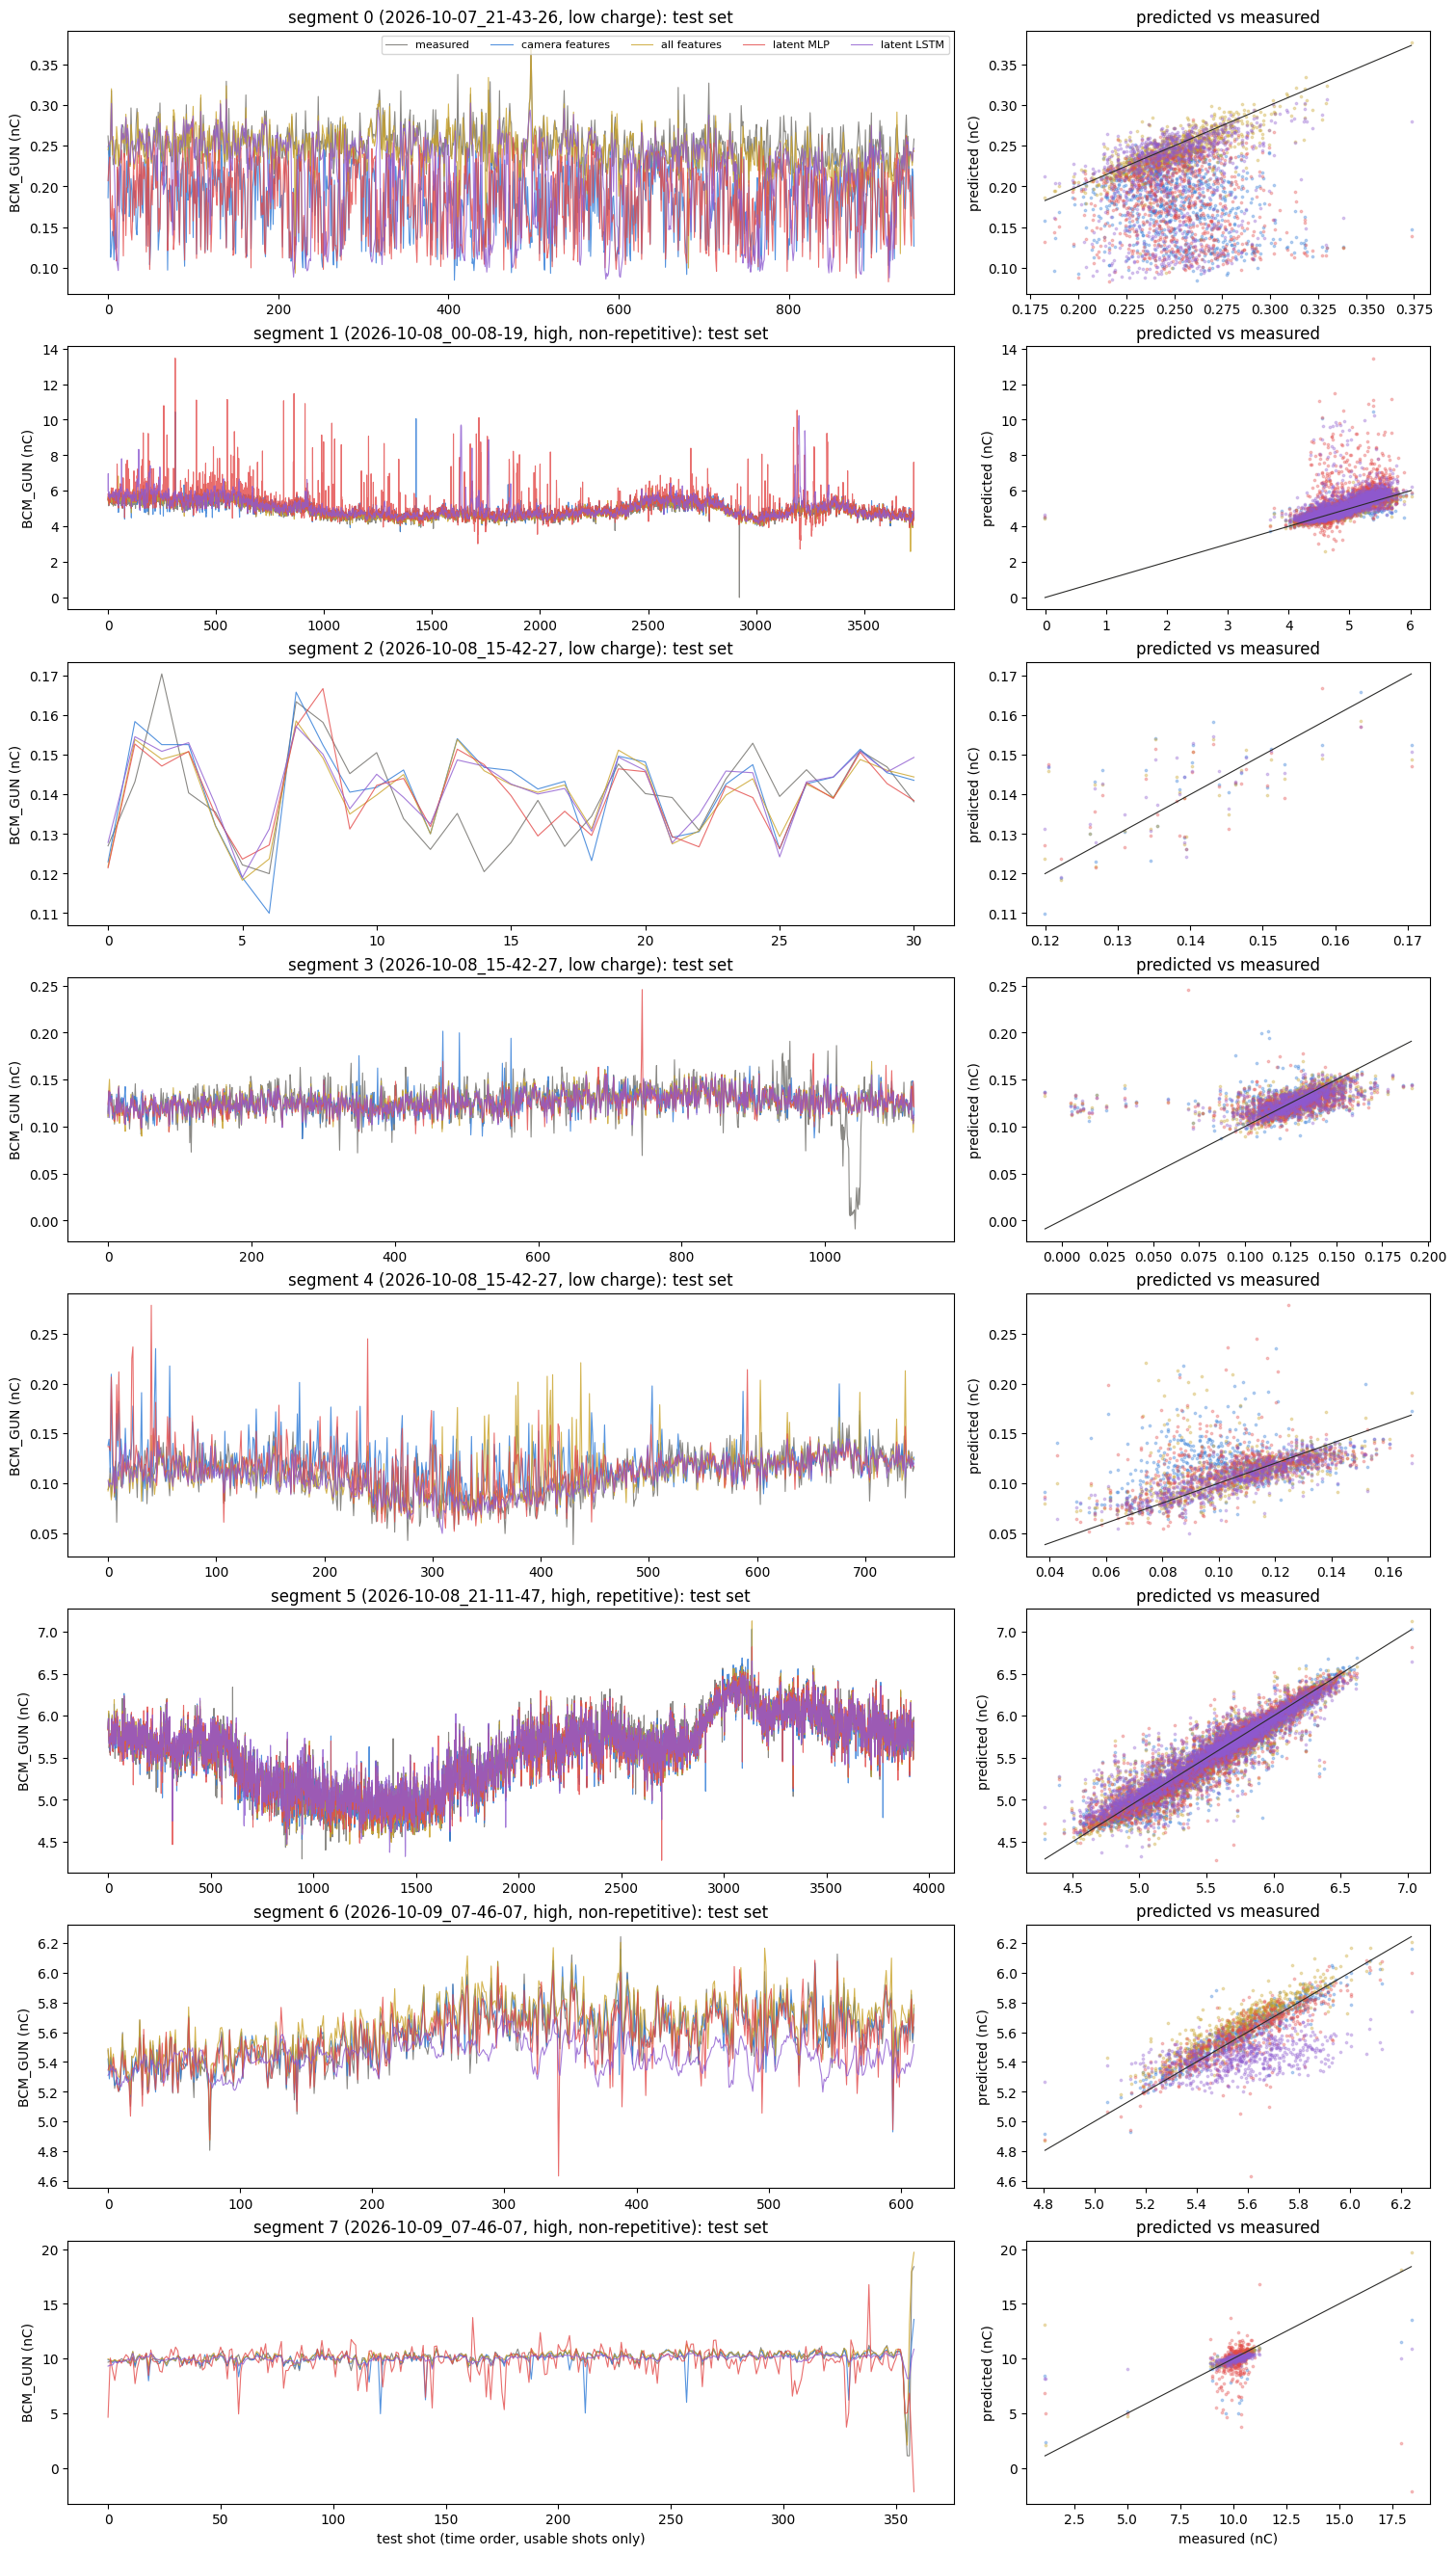

In [8]:
# the main models only, all of them are in the table
COLORS = {"camera features": "#2a78d6", "all features": "#c9a227", "latent LSTM": "#8e5bd0",
          "latent + features LSTM": "#1f9e78"}
fig, axes = plt.subplots(len(curves), 2, figsize=(15, 3.3 * len(curves)), gridspec_kw={"width_ratios": [2.2, 1]},
                         layout="constrained", squeeze=False)
for (ax1, ax2), (s, (y, p)) in zip(axes, sorted(curves.items())):
    shots = np.arange(len(y))
    ax1.plot(shots, y, color="#8a8985", lw=0.8, label="measured")
    for name, color in COLORS.items():
        ax1.plot(shots, p[name], color=color, lw=0.8, alpha=0.8, label=name)
        ax2.scatter(y, p[name], s=3, color=color, alpha=0.3)
    ax2.plot([y.min(), y.max()], [y.min(), y.max()], color="#2b2b29", lw=0.8)
    run = manifest["segments"][s]["run"].removeprefix("acquisition_")
    ax1.set(ylabel="BCM_GUN (nC)", title=f"segment {s} ({run}, {REGIME_OF[s]}): test set")
    ax2.set(ylabel="predicted (nC)", title="predicted vs measured")
axes[0, 0].legend(fontsize=8, ncols=5)
axes[-1, 0].set_xlabel("test shot (time order, usable shots only)")
axes[-1, 1].set_xlabel("measured (nC)")
plt.show()